# Bivariate Analysis — Relationships Between Variables

Two notebooks ago we found body mass varies wildly; last notebook we saw flipper length is
*bimodal*. Time to solve the mystery — and meet a famous statistical trap. Studying two
columns together is **bivariate analysis**.

### What you will learn

| Section | Topic |
|---------|-------|
| 1 | Numeric vs. categorical: grouping (which species is biggest?) |
| 2 | Numeric vs. numeric: scatter plots |
| 3 | Correlation and the correlation heatmap |
| 4 | Categorical vs. categorical: cross-tabulation |
| 5 | Adding a third variable with colour (`hue`) — solving the hook |
| 6 | **Simpson's paradox**: when a lurking variable reverses a correlation |

**Dataset:** Palmer Penguins (via seaborn).
        

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

print("Setup complete.")

Setup complete.


In [2]:
# The Palmer Penguins dataset ships with seaborn — no download needed.
df = sns.load_dataset("penguins")
print(f"Shape: {df.shape}")
df.head()

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


---
## Section 1 — Grouping: Which Species Is Biggest?

Grouping a numeric column by a category answers "does this differ between groups?".
        

In [3]:
df.groupby("species")["body_mass_g"].mean().round(0).sort_values(ascending=False)

species
Gentoo       5076.0
Chinstrap    3733.0
Adelie       3701.0
Name: body_mass_g, dtype: float64

Gentoo penguins are clearly the heaviest. A bar chart makes the gap obvious:

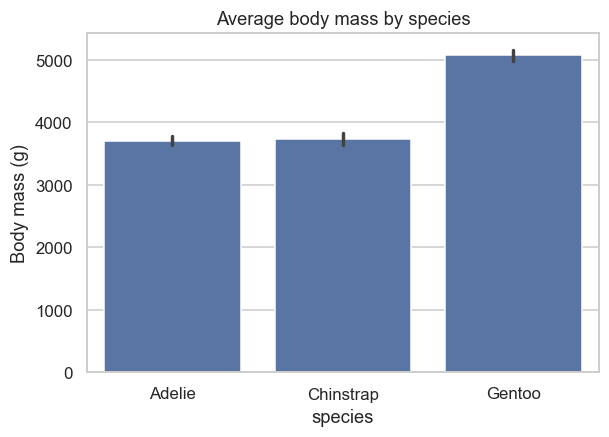

In [4]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="species", y="body_mass_g")   # bar height = mean body mass
plt.title("Average body mass by species")
plt.ylabel("Body mass (g)")
plt.show()
        

---
## Section 2 — Numeric vs. Numeric: Scatter Plots

A **scatter plot** puts one numeric variable on each axis, one dot per penguin.
*Do penguins with longer flippers also weigh more?*
        

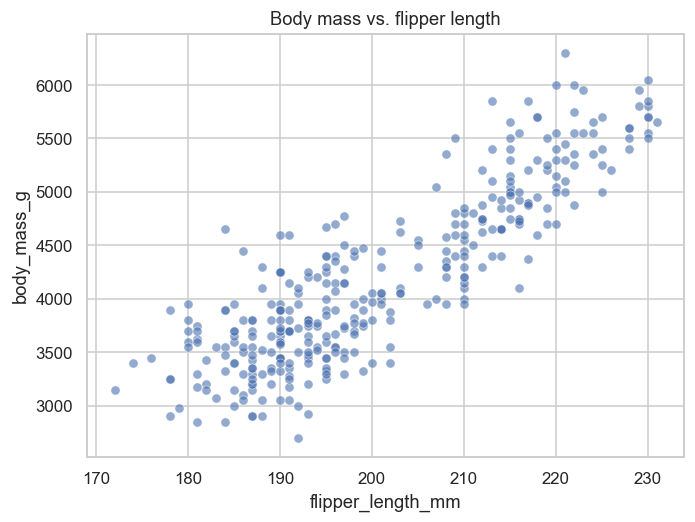

In [5]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g", alpha=0.6)
plt.title("Body mass vs. flipper length")
plt.show()
        

---
## Section 3 — Correlation

**Correlation** measures the strength and direction of a straight-line relationship, from
**−1 to +1** (0 = none). One pair, then all numeric columns as a **heatmap**:
        

In [6]:
df["flipper_length_mm"].corr(df["body_mass_g"]).round(3)

np.float64(0.871)

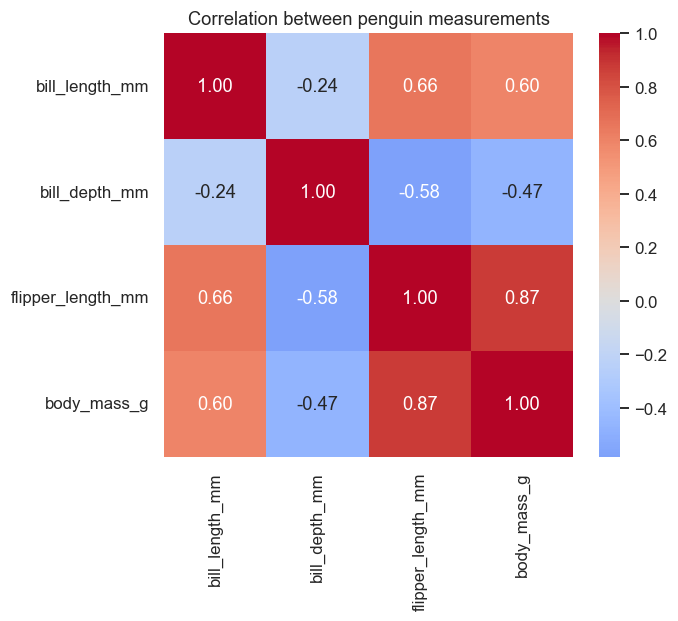

In [7]:
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between penguin measurements")
plt.show()
        

**Reading the heatmap:** the strongest relationship is flipper length ↔ body mass (~0.87).

---
## Section 4 — Categorical vs. Categorical: Cross-Tabulation

`pd.crosstab` counts the combinations of two categorical columns. *Where does each species
live?*
        

In [8]:
pd.crosstab(df["species"], df["island"])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


---
## Section 5 — Adding a Third Variable with Colour (solving the hook)

A scatter plot can show a **third** variable through colour (`hue`). Re-draw the
flipper-vs-mass plot, coloured by species:
        

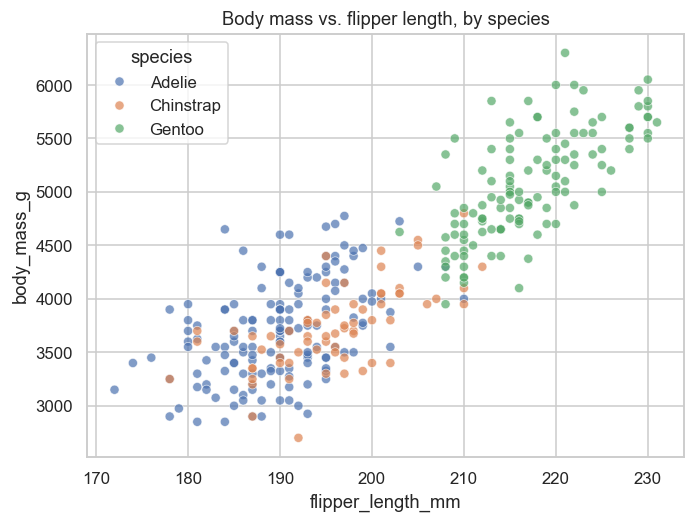

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g", hue="species", alpha=0.7)
plt.title("Body mass vs. flipper length, by species")
plt.show()
        

> The single cloud splits into **three clean clusters — one per
> species**. *That* is why body mass spread so widely (Notebook 1) and why flipper length
> was bimodal (Notebook 2): we were looking at three species blended together. The
> invisible cause behind the numbers is called a **lurking variable** — and here it is
> `species`.
        

---
## Section 6 — Simpson's Paradox: a Lurking Variable Reverses a Correlation

Lurking variables don't just explain spread — they can **flip a relationship's sign**.
Over the **whole** dataset, bill length and bill depth are *negatively* correlated:
        

In [10]:
print("Overall:", round(df["bill_length_mm"].corr(df["bill_depth_mm"]), 3))

Overall: -0.235


In [11]:
# ...but within EACH species the correlation is POSITIVE.
# (Selecting the two columns before .apply keeps this portable across pandas versions.)
df.groupby("species")[["bill_length_mm", "bill_depth_mm"]].apply(
    lambda g: g["bill_length_mm"].corr(g["bill_depth_mm"])
).round(3)
        

species
Adelie       0.391
Chinstrap    0.654
Gentoo       0.643
dtype: float64

>  **Finding — the correlation that lies.**
> Overall the correlation is **negative (≈ −0.24)**, yet inside *every* species it is
> **positive (≈ +0.4 to +0.65)**. The relationship literally **reverses** when you ignore
> species. This is **Simpson's paradox**. See it with your own eyes — note how each
> coloured group trends upward even though the whole cloud drifts downward:
        

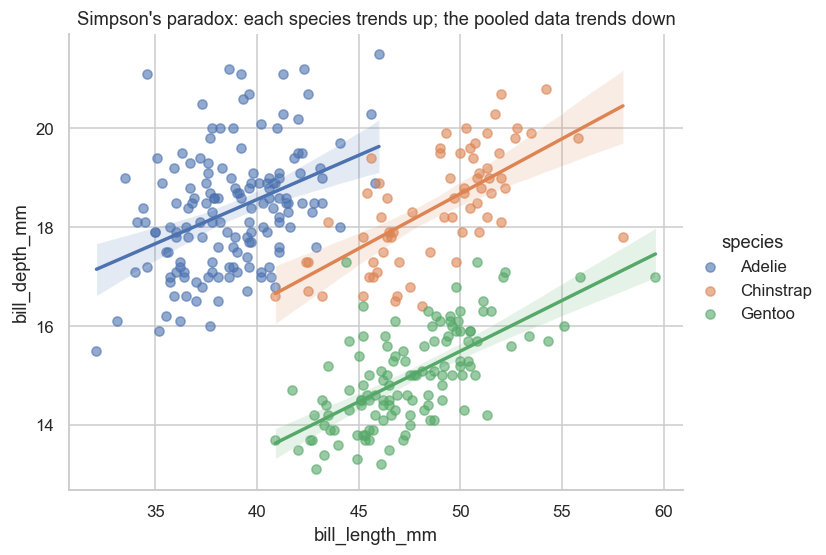

In [12]:
sns.lmplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species",
           height=5, aspect=1.3, scatter_kws={"alpha": 0.6})
plt.title("Simpson's paradox: each species trends up; the pooled data trends down")
plt.show()
        

**The lesson:** a correlation computed on pooled data can be **misleading or even
reversed**. Two things moving together — or apart — never proves causation. Always ask:
*"what group or third factor could be driving this?"*
        

---
## Key Takeaways

1. Pick the tool by the pair of types: scatter/`corr`/heatmap (numeric–numeric),
   `groupby`/box plot (numeric–categorical), `crosstab` (categorical–categorical).
2. **`hue`** adds a third variable to a scatter and often reveals **hidden clusters**.
3. A **lurking variable** can explain spread, create bimodality, and — via **Simpson's
   paradox** — *reverse* a correlation.
4. **Correlation ≠ causation.** Always look for confounders before believing a relationship.
        

---
## Exercises

1. **Means hide overlap.** Compute the **mean and the std** of `body_mass_g` for each
   `species` (or box-plot it: `sns.boxplot(data=df, x="species", y="body_mass_g")`). Gentoo
   are the heaviest — but do the species *overlap*? If someone told you a penguin weighs
   **4500 g**, could you confidently name its species? Explain why "compare the means" alone
   doesn't answer that.
2. **Make a scatter plot** of `bill_length_mm` (x) vs. `bill_depth_mm` (y), coloured by
   `species`. Describe what the colours reveal that a plain scatter hides.
3. Build a **cross-tab of `species` vs. `island`** with row percentages
   (`normalize="index"`). Which island is home to **only one** species?
4. **Make a box plot** of `body_mass_g` split by `sex` (`x="sex"`). Do males or females
   tend to be heavier?
5. **Does one number tell the truth?** From the **correlation heatmap**, name the
   *strongest* relationship and report its value. Then take `bill_length_mm` vs.
   `bill_depth_mm` — the heatmap shows a weak **negative** number. Make that scatter
   coloured by `species`. Does the single correlation value *honestly* summarise the
   relationship? Connect your answer to Simpson's paradox.
6. **Challenge (make the paradox undeniable):** Recreate the `sns.lmplot` from Section 6,
   then *also* fit a single trend line to the **pooled** data with
   `sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", scatter=False)`. Put both
   in one sentence: which way does the pooled line slope, and which way do the per-species
   lines slope?


---
## Exercise 1: Means hide overlap

In [13]:
# Compute mean and std of body mass by species
mass_stats = df.groupby("species")["body_mass_g"].agg(["mean", "std"]).round(0)
mass_stats

,mean,std
species,,
Adelie,3701.0,459.0
Chinstrap,3733.0,384.0
Gentoo,5076.0,504.0


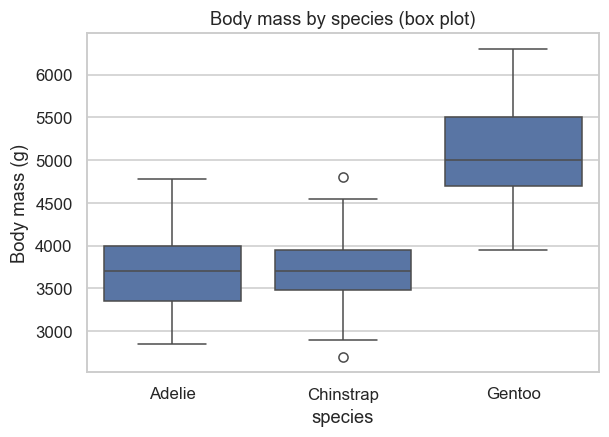

In [14]:
# Box plot to visualize overlap
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="species", y="body_mass_g")
plt.title("Body mass by species (box plot)")
plt.ylabel("Body mass (g)")
plt.show()

**Exercise 1 Answer:**

- Gentoo: mean ≈5076 g, std≈504 g
- Chinstrap: mean≈3733 g, std≈384 g
- Adelie: mean≈3701 g, std≈458 g

The species do overlap! For a 4500 g penguin, we cannot confidently name its species because:
- Gentoo's mean - std = 5076 - 504 = 4572 g, so 4500 g is just below that range
- Adelie and Chinstrap could have large outliers near 4500 g

"Compare the means" alone doesn't answer this because it ignores the **variation** within each species (standard deviation). Two groups can have different means but still have overlapping distributions.

---
## Exercise 2: Scatter plot coloured by species

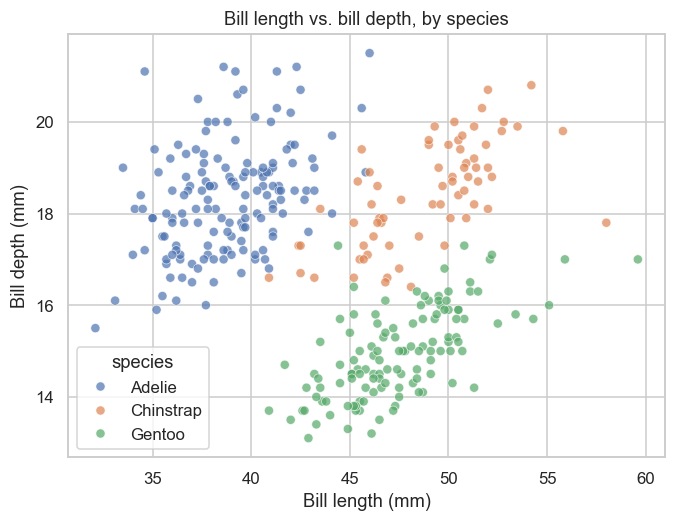

In [15]:
# Scatter plot of bill_length vs bill_depth, coloured by species
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.7)
plt.title("Bill length vs. bill depth, by species")
plt.xlabel("Bill length (mm)")
plt.ylabel("Bill depth (mm)")
plt.show()

**Exercise 2 Answer:**

The colours reveal **three distinct clusters**, one per species. A plain scatter plot would just show a messy cloud of points, but with colour we see:
- Adelie: shorter bill length, medium bill depth
- Chinstrap: longer bill length, medium bill depth
- Gentoo: medium-long bill length, shallower bill depth

Colour reveals the hidden structure that species creates!

---
## Exercise 3: Cross-tab with row percentages

In [16]:
# Cross-tab with row percentages
pd.crosstab(df["species"], df["island"], normalize="index").round(3)

island,Biscoe,Dream,Torgersen
species,,,
Adelie,0.289,0.368,0.342
Chinstrap,0.000,1.000,0.000
Gentoo,1.000,0.000,0.000


**Exercise 3 Answer:**

- **Biscoe** is home to only one species (Gentoo, 100% of Biscoe penguins are Gentoo).
- Torgersen also only has Adelie (100%).
- Dream has two species: Adelie and Chinstrap.

---
## Exercise 4: Body mass by sex

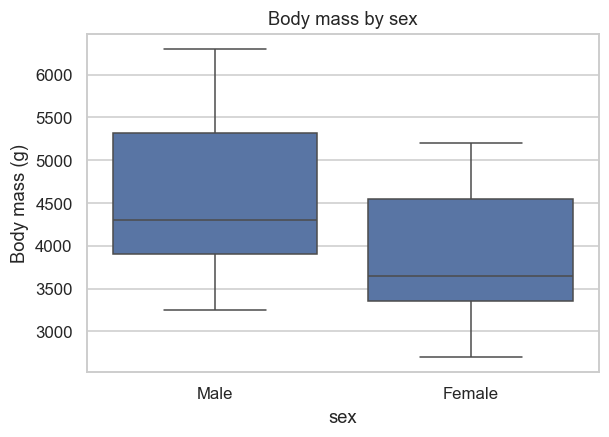

In [17]:
# Box plot of body mass by sex
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="sex", y="body_mass_g")
plt.title("Body mass by sex")
plt.ylabel("Body mass (g)")
plt.show()

**Exercise 4 Answer:**

**Males** tend to be heavier than females in this dataset.

---
## Exercise 5: Correlation and Simpson's paradox

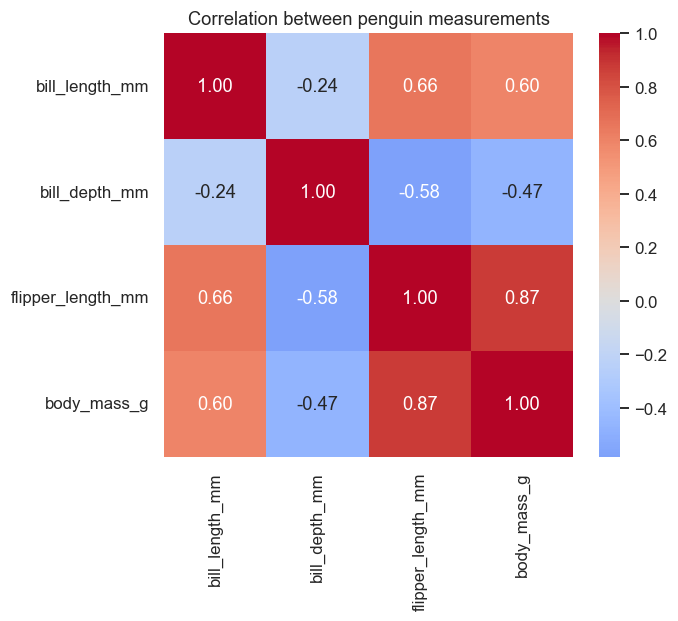

In [18]:
# Re-display correlation heatmap
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between penguin measurements")
plt.show()

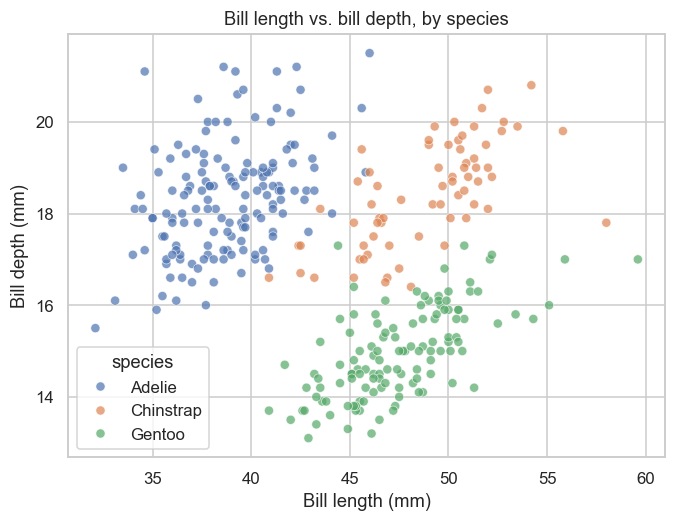

In [19]:
# Scatter plot of bill_length vs bill_depth, coloured by species
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.7)
plt.title("Bill length vs. bill depth, by species")
plt.xlabel("Bill length (mm)")
plt.ylabel("Bill depth (mm)")
plt.show()

**Exercise 5 Answer:**

The **strongest relationship** is `flipper_length_mm` vs. `body_mass_g`, with correlation ≈0.87.

For `bill_length_mm` vs. `bill_depth_mm`, the single negative correlation (≈-0.24) **does NOT honestly summarize** the relationship! As we saw in Section 6, within *each* species the correlation is positive (Adelie: +0.39, Chinstrap: +0.65, Gentoo: +0.64).

This is **Simpson's paradox** in action: the lurking variable `species` reverses the correlation when you pool all data together.

---
## Exercise 6: Challenge - Simpson's paradox visualization

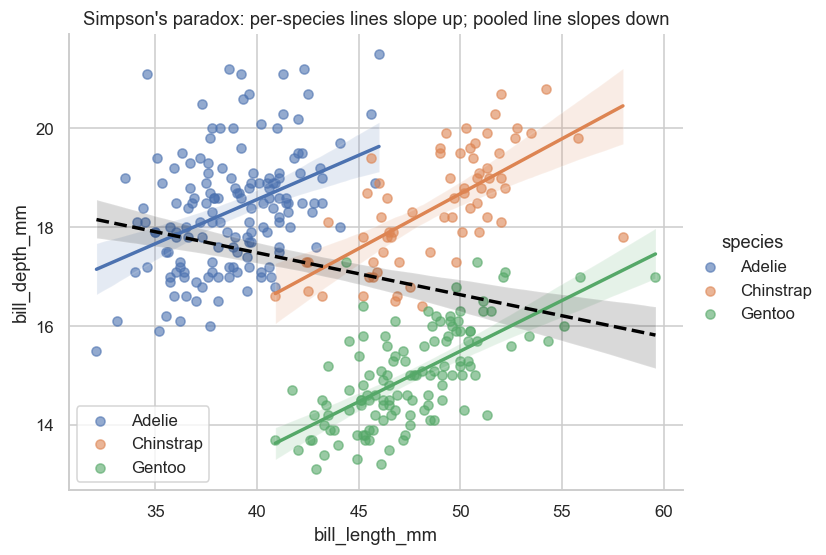

In [20]:
# Create the plot
g = sns.lmplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species",
               height=5, aspect=1.3, scatter_kws={"alpha": 0.6})

# Add pooled regression line (black)
sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", scatter=False,
            ax=g.ax, color="black", line_kws={"linestyle": "--", "label": "Pooled"})

plt.title("Simpson's paradox: per-species lines slope up; pooled line slopes down")
plt.legend()
plt.show()

**Exercise 6 Answer:**

The **pooled (black dashed) line slopes downward**, while the **per-species (coloured) lines slope upward**! This is a dramatic visual proof of Simpson's paradox.